This notebook shows how astigmatic images can be created from phase and amplitude objects. First, import the necessary functions:


In [11]:
import sys
sys.path.append("../src/focalseriesrecon")

import numpy as np

from utils import *
from optics import *
from specimen import *

We can create a pure phase-object and a pure ampitude object:

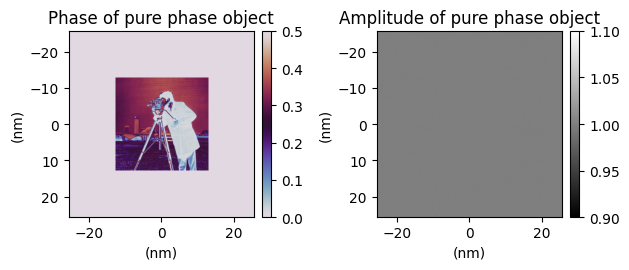

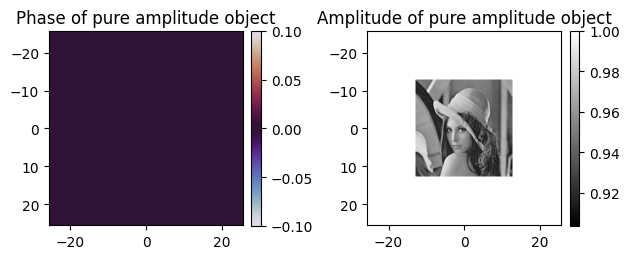

In [12]:
phase_obj = Specimen(phase_source='../images/cameraman512.jpg', phase_strength=0.5, resize_img=512, pixel_size=0.05)
amp_obj = Specimen(amp_source='../images/lena_1.jpg', amp_strength=0.1, resize_img=512, pixel_size=0.05)

fig, ax1 = plt.subplots(1, 2)
plot_2d(phase_obj.owf, x=phase_obj.x, y=phase_obj.y, mode="phase", title="Phase of pure phase object", xlabel="(nm)", ylabel="(nm)", ax=ax1[0])
plot_2d(phase_obj.owf, x=phase_obj.x, y=phase_obj.y, mode="abs", title="Amplitude of pure phase object", xlabel="(nm)", ylabel="(nm)", ax=ax1[1])
plt.tight_layout()

fig, ax2 = plt.subplots(1, 2)
plot_2d(amp_obj.owf, x=amp_obj.x, y=amp_obj.y, mode="phase", title="Phase of pure amplitude object", ax=ax2[0])
plot_2d(amp_obj.owf, x=amp_obj.x, y=amp_obj.y, mode="abs", title="Amplitude of pure amplitude object", ax=ax2[1])
plt.tight_layout()

The image wavefunctions are given by fourier transforming, applying the contrast transfer function, and inverse fourier transforming. First, we can generate the contrast transfer function:

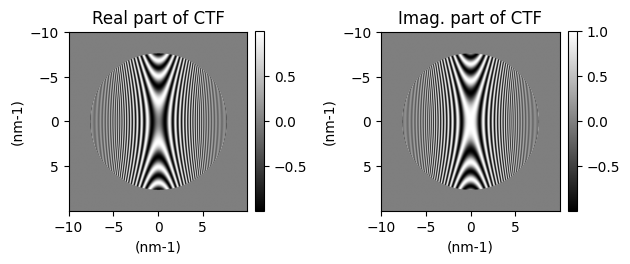

In [13]:
acc_voltage = 300
wavelength = electron_wavelength(acc_voltage)
cs=1e4
defocus_x=500
defocus_y=-50
aperture_alpha_max=15

ctf_values_2d = ctf_complex_astig(phase_obj.K_X, phase_obj.K_Y, wavelength, defocus_x, defocus_y, cs) * aperture_grid(phase_obj.k_grid, wavelength, aperture_alpha_max)
fig, ax3 = plt.subplots(1, 2)
plot_2d(ctf_values_2d, x=phase_obj.kx, y=phase_obj.ky, mode="imag", title="Real part of CTF", xlabel="(nm-1)", ylabel="(nm-1)", ax=ax3[0])
plot_2d(ctf_values_2d, x=phase_obj.kx, y=phase_obj.ky, mode="real", title="Imag. part of CTF", xlabel="(nm-1)", ylabel="(nm-1)", ax=ax3[1])
plt.tight_layout()

We can now generate the image wave functions by multiplying by the CTF in reciprocal space. The intensity is then found by taking the modulus squared.

Text(0.5, 0.98, 'Intensities')

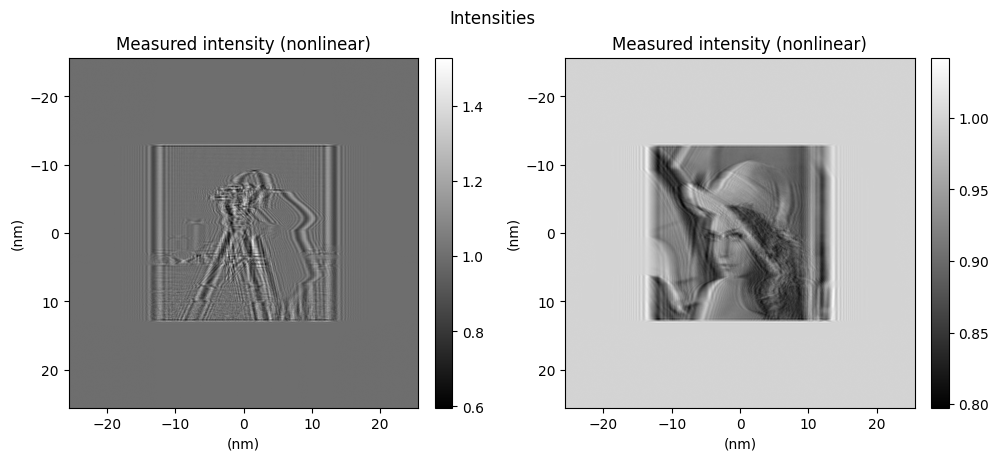

In [ ]:
phase_obj_intensity_nonlinear = forward_nonlinear_astig(phase_obj.owf, phase_obj.k_grid, phase_obj.K_X, phase_obj.K_Y, wavelength, defocus_x, defocus_y, cs, aperture_alpha_max)
amp_obj_intensity_nonlinear = forward_nonlinear_astig(amp_obj.owf, amp_obj.k_grid, amp_obj.K_X, amp_obj.K_Y, wavelength, defocus_x, defocus_y, cs, aperture_alpha_max)

fig, ax4 = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
plot_2d(phase_obj_intensity_nonlinear, x=phase_obj.x, y=phase_obj.y, title="Measured intensity (phase obj.)", xlabel="(nm)", ylabel="(nm)", ax=ax4[0])
plot_2d(amp_obj_intensity_nonlinear, x=amp_obj.x, y=amp_obj.y, title="Measured intensity (amplitude obj.)", xlabel="(nm)", ylabel="(nm)", ax=ax4[1])
fig.suptitle("Intensities")

We can now also generate defocus series by doing what we have done multiple times for different defocus values.

(<Figure size 1250x1250 with 25 Axes>,
 array([<Axes: title={'center': 'Δfx = -100, Δfy = -100nm'}>,
        <Axes: title={'center': 'Δfx = -100, Δfy = -50nm'}>,
        <Axes: title={'center': 'Δfx = -100, Δfy = 0nm'}>,
        <Axes: title={'center': 'Δfx = -100, Δfy = 50nm'}>,
        <Axes: title={'center': 'Δfx = -100, Δfy = 100nm'}>,
        <Axes: title={'center': 'Δfx = -50, Δfy = -100nm'}>,
        <Axes: title={'center': 'Δfx = -50, Δfy = -50nm'}>,
        <Axes: title={'center': 'Δfx = -50, Δfy = 0nm'}>,
        <Axes: title={'center': 'Δfx = -50, Δfy = 50nm'}>,
        <Axes: title={'center': 'Δfx = -50, Δfy = 100nm'}>,
        <Axes: title={'center': 'Δfx = 0, Δfy = -100nm'}>,
        <Axes: title={'center': 'Δfx = 0, Δfy = -50nm'}>,
        <Axes: title={'center': 'Δfx = 0, Δfy = 0nm'}>,
        <Axes: title={'center': 'Δfx = 0, Δfy = 50nm'}>,
        <Axes: title={'center': 'Δfx = 0, Δfy = 100nm'}>,
        <Axes: title={'center': 'Δfx = 50, Δfy = -100nm'}>,
        <Axe

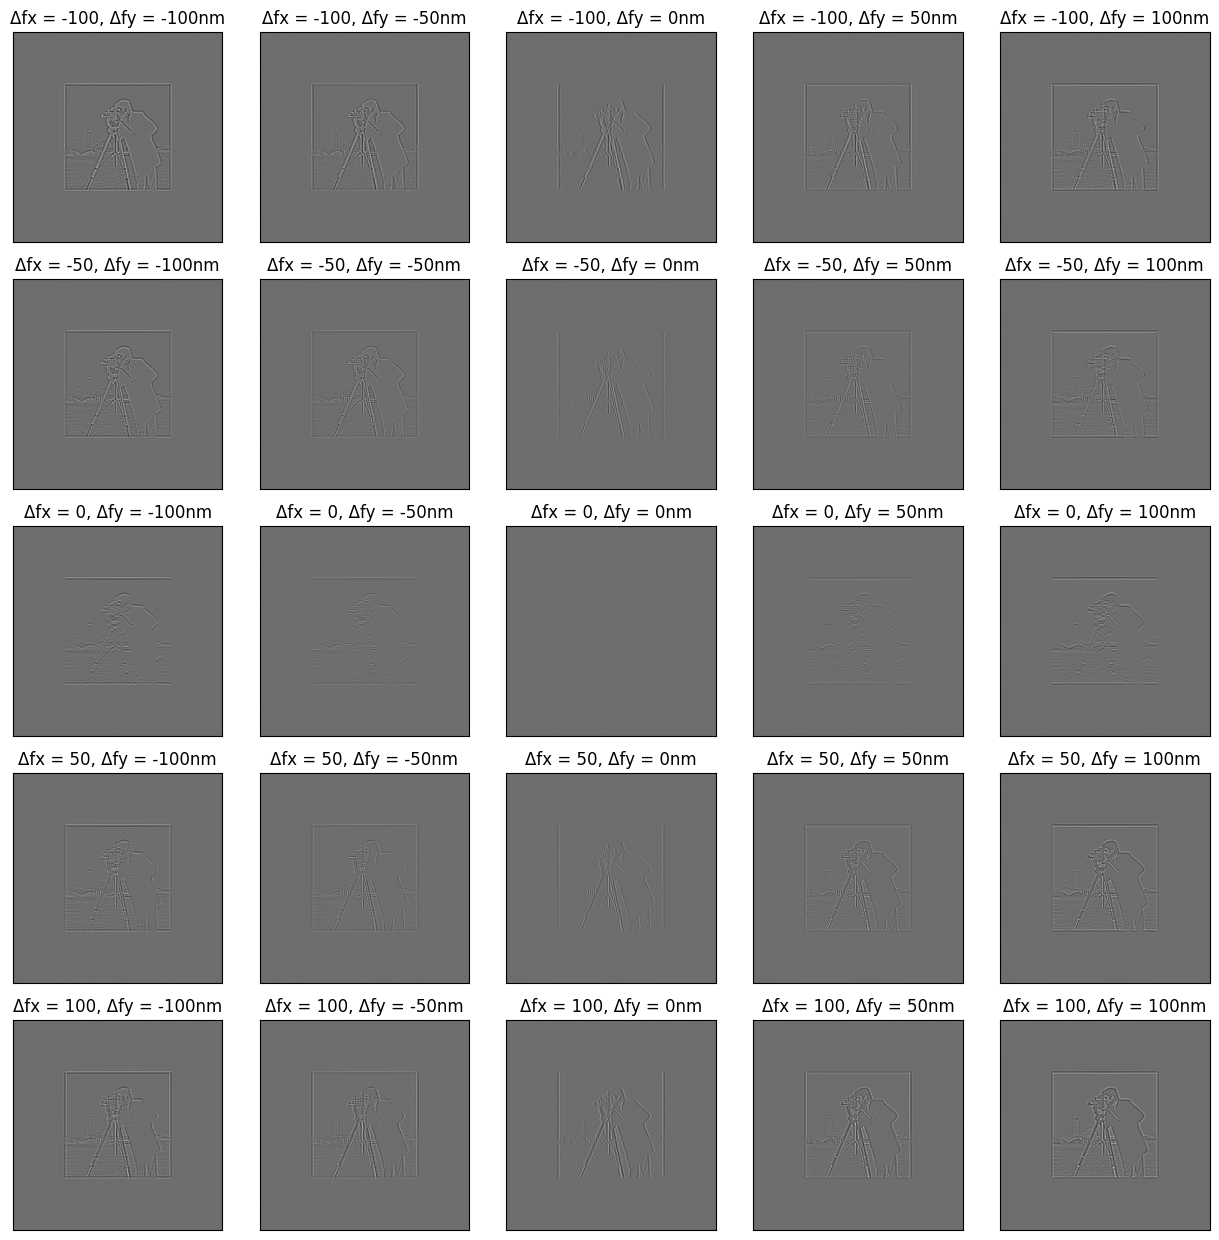

In [15]:
defoci_x = np.linspace(-100, 100, 5)
defoci_y = np.linspace(-100, 100, 5)

# Make every combination
defoci_x, defoci_y = meshflatten(defoci_x, defoci_y)
phase_obj_focal_series = focal_series_astig(defoci_x, defoci_y, phase_obj.owf, phase_obj.k_grid, phase_obj.K_X, phase_obj.K_Y, wavelength, cs, aperture_alpha_max)

plot_focal_series(phase_obj_focal_series, defoci_x, defoci_y)